# 10. Deslocamento para o tratamento

O caderno 09 mostrou onde estão os equipamentos e os hospitais. Este caderno mede a outra ponta: quanto as mulheres precisam viajar para se tratar. Ele responde em quatro partes. A primeira mede, para cada município, a distância até o hospital oncológico mais próximo. A segunda mede quanto as pacientes do SUS viajaram de fato para o primeiro tratamento. A terceira compara a distância percorrida em cada tipo de tratamento: cirurgia, quimioterapia, hormonioterapia, terapia anti-HER2 e radioterapia. A quarta verifica se viajar mais está associado a chegar com a doença mais avançada.

Todas as distâncias são calculadas em linha reta entre o centro do município onde a paciente mora e o centro do município onde ela foi atendida. A distância real por estrada, ou por rio na Amazônia, é sempre maior; os números aqui são, portanto, um limite mínimo. Quando a paciente é atendida no próprio município, a distância é zero.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g
from mama.config import FONTE_CNES, FONTE_PAINEL, FONTE_RHC
from mama.analises import base, deslocamento as desl, estadiamento as est

pd.set_option("display.max_columns", 20)
CORES_KM = dict(zip(desl.FAIXAS_KM_ROTULOS, ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))

## Distância até o centro de tratamento mais próximo

Para cada um dos 5.570 municípios, calculamos a distância em linha reta até o município mais próximo que tem UNACON ou CACON. O mapa pinta cada município pela faixa de distância.

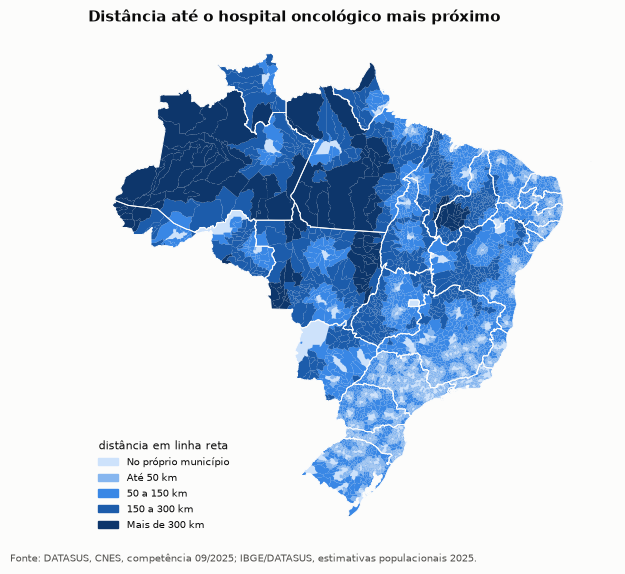

In [2]:
dist_mun = desl.distancia_ao_servico_mais_proximo("UNACON/CACON")
base.salvar_tabela(dist_mun, "10_distancia_municipio_ate_unacon_cacon")
classes = ["No próprio município", "Até 50 km", "50 a 150 km", "150 a 300 km", "Mais de 300 km"]
fig, ax = g.mapa_municipios(dist_mun.set_index("mun").km_servico_mais_proximo,
                            "Distância até o hospital oncológico mais próximo", "distância em linha reta",
                            [-0.1, 0.1, 50, 150, 300, 5000], classes)
g.salvar(fig, "10_mapa_distancia_centro_oncologia", FONTE_CNES)
plt.show()

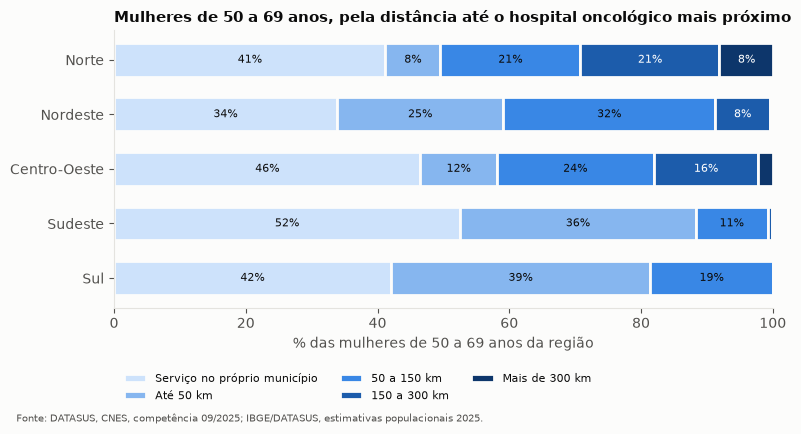

                         nome  uf  km_servico_mais_proximo  \
105                    Japurá  AM               902.030045   
125  São Gabriel da Cachoeira  AM               864.880326   
132                 Tonantins  AM               817.514984   
124      Santo Antônio do Içá  AM               783.683581   
75                    Amaturá  AM               739.174618   

    municipio_servico_mais_proximo  
105                         Manaus  
125                      Boa Vista  
132                    Porto Velho  
124                     Rio Branco  
75                      Rio Branco  


In [3]:
pop_dist = desl.populacao_por_faixa_de_distancia(dist_mun, "mulheres_50_69")
base.salvar_tabela(pop_dist, "10_mulheres_50_69_por_distancia", index=True)
fig, ax = g.empilhadas_100(pop_dist, "Mulheres de 50 a 69 anos, pela distância até o hospital oncológico mais próximo",
                           "% das mulheres de 50 a 69 anos da região",
                           cores=dict(zip(pop_dist.columns, ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])),
                           figsize=(8.5, 3.6))
g.salvar(fig, "10_mulheres_por_distancia", FONTE_CNES)
plt.show()
print(dist_mun.nlargest(5, "km_servico_mais_proximo")[["nome", "uf", "km_servico_mais_proximo", "municipio_servico_mais_proximo"]])

No Sul e no Sudeste, praticamente nenhuma mulher na faixa do rastreamento vive a mais de 150 km de um hospital oncológico. No Norte, 29% vivem a mais de 150 km, e 8% a mais de 300 km. No Centro-Oeste são 18% acima de 150 km. Os municípios mais isolados ficam no Amazonas, a 700 a 900 km em linha reta do centro mais próximo, uma viagem que na prática é feita de barco ou avião.

## Quanto as pacientes realmente viajaram

As seções anteriores falam do serviço mais próximo. Mas a paciente nem sempre é atendida no serviço mais próximo: ela vai para onde a regulação do SUS a encaminha. O Painel de Oncologia informa o município onde a paciente mora e o município onde fez o primeiro tratamento. Com isso, medimos o deslocamento real.

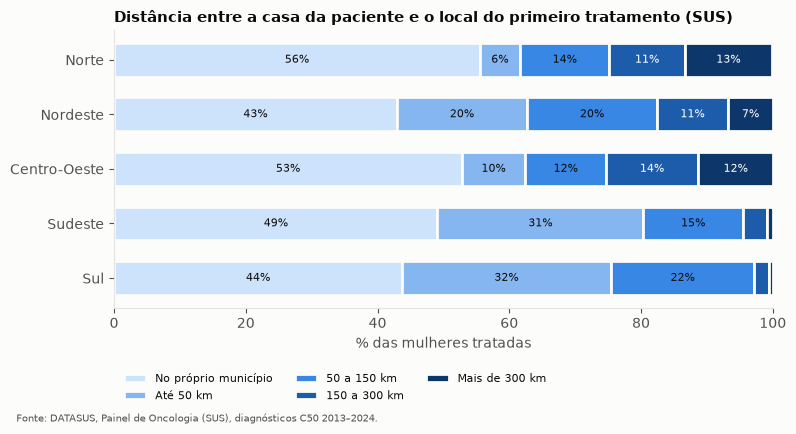

,regiao_res,n,pct_outro_municipio,mediana_km_quem_viaja,pct_mais_150km,pct_mais_300km
0,Centro-Oeste,31480,47.2,167.9,25.4,11.5
1,Nordeste,114986,57.1,80.5,17.7,6.8
2,Norte,20328,44.5,172.2,24.7,13.3
3,Sudeste,226008,50.9,38.2,4.5,0.9
4,Sul,101759,56.3,43.9,2.8,0.7


In [4]:
painel = base.painel()
viagem = desl.adicionar_distancia(painel[painel.tratado], "mun_res", "mun_trat")
dist_viagem = desl.distribuicao_distancia(viagem)
resumo_viagem = desl.resumo_distancia(viagem, ["regiao_res"])
base.salvar_tabela(dist_viagem, "10_painel_distancia_tratamento_regiao", index=True)
base.salvar_tabela(resumo_viagem, "10_painel_resumo_distancia_regiao")
fig, ax = g.empilhadas_100(dist_viagem, "Distância entre a casa da paciente e o local do primeiro tratamento (SUS)",
                           "% das mulheres tratadas",
                           cores=dict(zip(desl.FAIXAS_KM_ROTULOS, ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])),
                           figsize=(8.5, 3.6))
g.salvar(fig, "10_distancia_percorrida_regiao", FONTE_PAINEL)
plt.show()
resumo_viagem

Em todas as regiões, cerca de metade das mulheres precisa sair do próprio município para começar o tratamento. A diferença está na distância. No Sul e no Sudeste, quem viaja percorre, em mediana, cerca de 40 km. No Norte e no Centro-Oeste, a mediana passa de 165 km, e 13% das mulheres do Norte viajam mais de 300 km. No Nordeste, a mediana é de 80 km, e 18% viajam mais de 150 km.

## A distância muda conforme o tipo de tratamento

Cada etapa do tratamento acontece em um tipo de serviço diferente, e alguns são muito mais raros que outros. Para comparar, juntamos as fontes que registram o município da paciente e o do serviço. A cirurgia vem do Painel de Oncologia (quando ela é o primeiro tratamento). A quimioterapia, a hormonioterapia e a terapia anti-HER2 vêm da APAC de quimioterapia de 2024, considerando uma vez cada paciente em cada tipo de tratamento. A radioterapia vem da APAC de radioterapia de 2023 e 2024.

A mamografia não entra nesta comparação porque o SISCAN público não informa o município onde o exame foi feito. Para ela, a medida disponível é a distância até o mamógrafo do SUS mais próximo, apresentada no caderno 09.

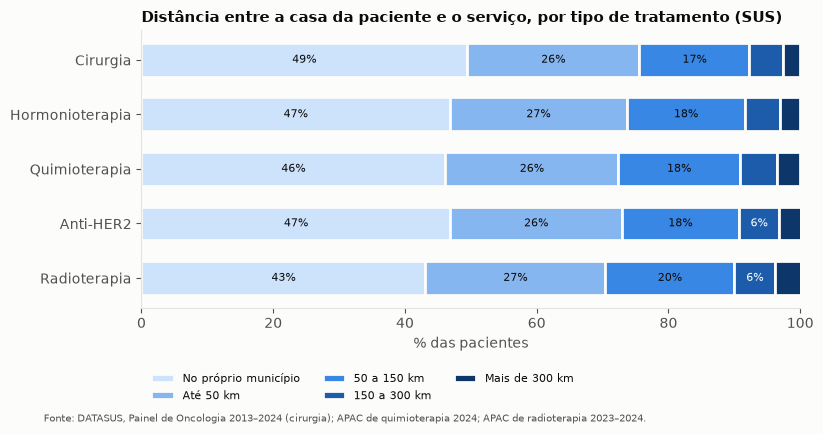

,n,pct_outro_municipio,mediana_km_quem_viaja,pct_mais_150km,pct_mais_300km
tipo,,,,,
Cirurgia,88559,50.6,48.3,7.7,2.6
Hormonioterapia,193385,53.2,49.3,8.3,3.0
Quimioterapia,65355,53.9,51.5,9.2,3.5
Anti-HER2,22149,53.1,51.2,9.4,3.3
Radioterapia,68624,56.9,53.3,10.1,3.9


In [5]:
trat = desl.distancias_por_tratamento()
ORDEM_TRAT = ["Cirurgia", "Hormonioterapia", "Quimioterapia", "Anti-HER2", "Radioterapia"]
dist_tipo = desl.distribuicao_distancia(trat, "tipo").reindex(ORDEM_TRAT)
resumo_tipo = desl.resumo_distancia(trat, ["tipo"]).set_index("tipo").reindex(ORDEM_TRAT)
base.salvar_tabela(dist_tipo, "10_distancia_por_tipo_tratamento", index=True)
base.salvar_tabela(resumo_tipo, "10_resumo_distancia_por_tipo_tratamento", index=True)
fig, ax = g.empilhadas_100(dist_tipo, "Distância entre a casa da paciente e o serviço, por tipo de tratamento (SUS)",
                           "% das pacientes", cores=CORES_KM, figsize=(8.5, 3.6))
g.salvar(fig, "10_distancia_por_tipo_tratamento", "DATASUS, Painel de Oncologia 2013–2024 (cirurgia); "
         "APAC de quimioterapia 2024; APAC de radioterapia 2023–2024.")
plt.show()
resumo_tipo

No país como um todo, as diferenças entre os tratamentos são menores do que se poderia esperar: em todos eles, cerca de metade das mulheres sai do próprio município, e quem viaja percorre, em mediana, cerca de 50 km. Ainda assim, há uma ordem clara. A cirurgia é a etapa mais próxima de casa (51% saem do município, 8% viajam mais de 150 km). A radioterapia é a mais distante (57% saem do município, 10% viajam mais de 150 km e 4% mais de 300 km), porque depende de aparelhos que existem em poucos lugares.

A hormonioterapia merece um comentário. Na distância, ela parece igual às outras. Mas ela dura de 5 a 10 anos, e o medicamento é entregue pelo hospital, em geral a cada mês. Uma mulher que mora a 150 km do hospital repete essa viagem dezenas de vezes. O impacto do deslocamento, portanto, não depende só da distância, mas também de quantas vezes ela precisa ser percorrida.

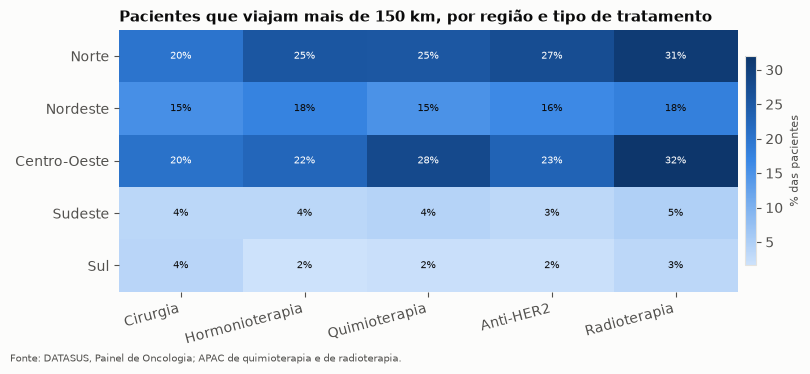

tipo,Cirurgia,Hormonioterapia,Quimioterapia,Anti-HER2,Radioterapia
regiao_res,,,,,
Norte,20.0,25.4,25.3,27.2,30.8
Nordeste,15.4,17.5,15.0,16.4,17.9
Centro-Oeste,20.4,22.4,27.9,23.0,32.0
Sudeste,3.5,3.6,4.2,3.3,4.7
Sul,3.8,1.6,2.0,1.9,3.4


In [6]:
por_regiao_tipo = desl.resumo_distancia(trat, ["regiao_res", "tipo"])
base.salvar_tabela(por_regiao_tipo, "10_resumo_distancia_regiao_tipo")
mais150 = por_regiao_tipo.pivot(index="regiao_res", columns="tipo", values="pct_mais_150km").reindex(index=c.REGIOES, columns=ORDEM_TRAT)
fig, ax = g.calor(mais150, "Pacientes que viajam mais de 150 km, por região e tipo de tratamento",
                  "% das pacientes", fmt="{:.0f}%", figsize=(9.5, 3.4))
ax.set_xticks(range(len(ORDEM_TRAT)), ORDEM_TRAT, rotation=15, ha="right")
g.salvar(fig, "10_mais_150km_regiao_tipo", "DATASUS, Painel de Oncologia; APAC de quimioterapia e de radioterapia.")
plt.show()
mais150

Separando por região, a diferença aparece com força. No Sul e no Sudeste, menos de 5% das pacientes viajam mais de 150 km, qualquer que seja o tratamento. No Norte e no Centro-Oeste, entre 20% e 32% viajam mais de 150 km, e a radioterapia é o pior caso nas duas regiões: 31% no Norte e 32% no Centro-Oeste. No Nordeste, os valores ficam entre 15% e 18%. Para quem viaja, a mediana no Norte passa de 170 km em quase todos os tratamentos, contra cerca de 40 km no Sudeste.

## Os polos de atendimento

Alguns municípios funcionam como polos que recebem pacientes de muitos outros. A tabela lista os dez que mais recebem mulheres de fora.

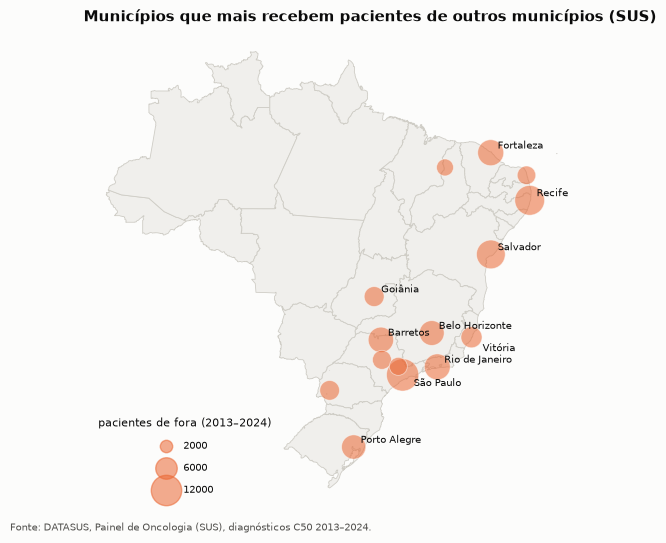

,nome,uf,pacientes_de_fora,municipios_de_origem
0,São Paulo,SP,13478,297
1,Recife,PE,11455,305
2,Salvador,BA,10688,454
3,Fortaleza,CE,8755,216
4,Rio de Janeiro,RJ,8674,116
5,Barretos,SP,8352,908
6,Belo Horizonte,MG,7960,337
7,Porto Alegre,RS,7621,196
8,Vitória,ES,5765,124
9,Goiânia,GO,5147,249


In [7]:
polos = desl.polos_de_atendimento(viagem, "mun_res", "mun_trat", 15)
base.salvar_tabela(polos, "10_polos_de_atendimento")
fig, ax = g.mapa_pontos(polos, "pacientes_de_fora", "Municípios que mais recebem pacientes de outros municípios (SUS)",
                        "pacientes de fora (2013–2024)", escala=0.04, cor=g.CATEGORICAS[1],
                        legenda_valores=[2000, 6000, 12000])
ajuste = {"Vitória": (8, -10), "São Paulo": (8, -8)}  # evita rótulos sobrepostos
for _, r in polos.head(10).iterrows():
    ax.annotate(r.nome, (r.lon, r.lat), xytext=ajuste.get(r.nome, (5, 3)), textcoords="offset points", fontsize=7)
g.salvar(fig, "10_mapa_polos", FONTE_PAINEL)
plt.show()
polos.head(10)[["nome", "uf", "pacientes_de_fora", "municipios_de_origem"]]

As capitais dominam a lista, como esperado. A exceção é Barretos, no interior de São Paulo, sede do Hospital de Amor: com cerca de 120 mil habitantes, ele recebe mulheres de mais de 900 municípios diferentes, mais do que qualquer capital. É um exemplo de como um único centro de referência pode concentrar a demanda de uma área enorme do país.

## Distância e estádio ao diagnóstico

Viajar mais está associado a chegar com a doença mais avançada? O RHC permite cruzar a distância entre a casa e o hospital com o estádio.

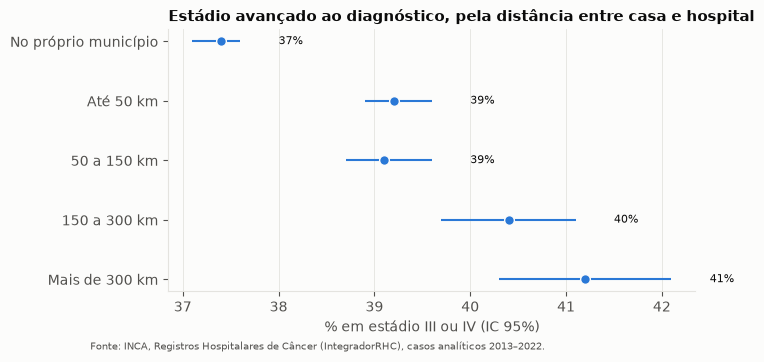

,faixa_distancia,n,eventos,pct,ic_inf,ic_sup
0,No próprio município,121783,45508,37.4,37.1,37.6
1,Até 50 km,69158,27143,39.2,38.9,39.6
2,50 a 150 km,46445,18171,39.1,38.7,39.6
3,150 a 300 km,19182,7753,40.4,39.7,41.1
4,Mais de 300 km,12107,4989,41.2,40.3,42.1


In [8]:
rhc = desl.adicionar_distancia(base.rhc(), "mun_res", "mun_hosp")
est_dist = est.avancado(rhc.dropna(subset=["faixa_distancia"]), ["faixa_distancia"])
base.salvar_tabela(est_dist, "10_estadio_avancado_por_distancia")
fig, ax = g.pontos_ic(est_dist.assign(todas="Todas"), "faixa_distancia", "todas",
                      "Estádio avançado ao diagnóstico, pela distância entre casa e hospital",
                      "% em estádio III ou IV (IC 95%)", ordem_cat=desl.FAIXAS_KM_ROTULOS, figsize=(6.8, 3.4))
g.salvar(fig, "10_estadio_por_distancia", FONTE_RHC)
plt.show()
est_dist

Há um gradiente: 37% de estádio avançado entre mulheres tratadas no próprio município e 41% entre as que viajam mais de 300 km. A diferença é menor do que as diferenças por região ou raça/cor, mas é consistente e cresce a cada faixa de distância.

## O que levar para o TCC

Metade das mulheres tratadas pelo SUS precisa sair do próprio município para se tratar, em qualquer etapa. A radioterapia é a etapa que exige as viagens mais longas, e a hormonioterapia, embora não seja mais distante, obriga a repetir a viagem por anos. No Norte e no Centro-Oeste, entre um quinto e um terço das pacientes viaja mais de 150 km, contra menos de 5% no Sul e no Sudeste. Quanto mais longe o hospital, maior a proporção de mulheres que chegam com a doença avançada. Esses resultados mostram o custo, para as pacientes, da concentração de serviços descrita no caderno 09, e sustentam o argumento do projeto por formas de acompanhamento que possam ser feitas mais perto de casa.